# Goal 01 — Statistical Analysis

## Task 03: Exploratory Data Analysis (EDA)

### Objective

Explore the concrete dataset using descriptive statistics
and visualizations to understand the distributions of
ingredients, curing age, and concrete strength.

### Research Questions

1. How are concrete strength values distributed?
2. What are the typical ingredient quantities?
3. What patterns exist between ingredients and strength?
4. How does curing age relate to strength?
5. What unusual patterns require further investigation?


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the processed dataset
paths = [
    Path("data/processed/concrete_clean.csv"),
    Path("../data/processed/concrete_clean.csv")
]

data_path = next((p for p in paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("Processed dataset not found.")

# Load the data
df = pd.read_csv(data_path)


# Set up output directory
project_root = data_path.parent.parent.parent
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# Configure plot style
sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
# Summary statistics for all variables
summary = df.describe().T
display(summary.round(2))



,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
blast_furnace_slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
coarse_aggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_aggregate,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


### 3.1 Descriptive Statistics

Summary statistics were calculated for all numerical
variables to understand their typical values, ranges,
and variability.

#### Key Observations

- Mean concrete strength: 35.82 MPa
- Median concrete strength: 34.44 MPa
- Minimum concrete strength: 2.33 MPa
- Maximum concrete strength: 82.6 MPa
- Standard deviation of strength: 16.71 MPa


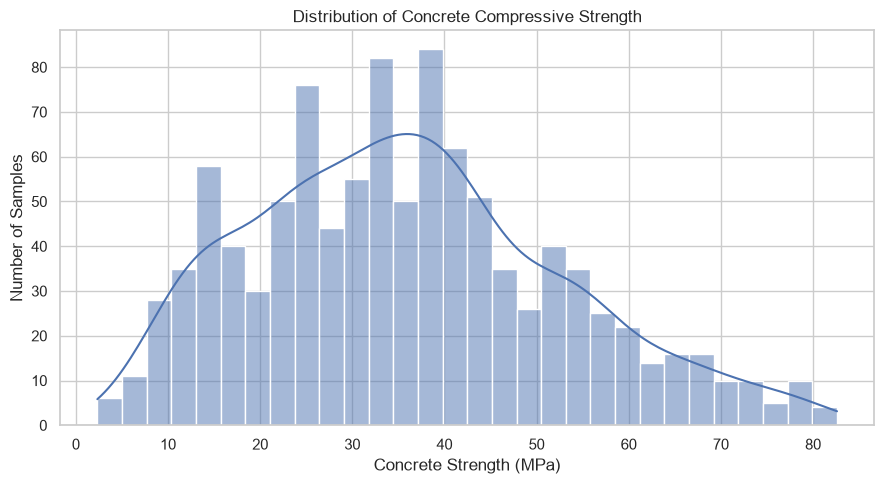

In [5]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="strength",
    bins=30,
    kde=True
)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Concrete Strength (MPa)")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.savefig(fig_dir / "strength_distribution.png", dpi=300)
plt.show()


### Concrete Strength Distribution — Observations

- Most concrete samples have compressive strengths between approximately 20 and 45 MPa.
- The highest concentration of samples occurs around 30–40 MPa.
- The distribution is roughly unimodal with a slight right skew.
- Relatively few samples have strengths above 70 MPa.
- The observed strength range is approximately 2–83 MPa.

**Conclusion:** Concrete strength varies considerably across the dataset, with most samples concentrated in the moderate-strength range and fewer samples at very high strengths.


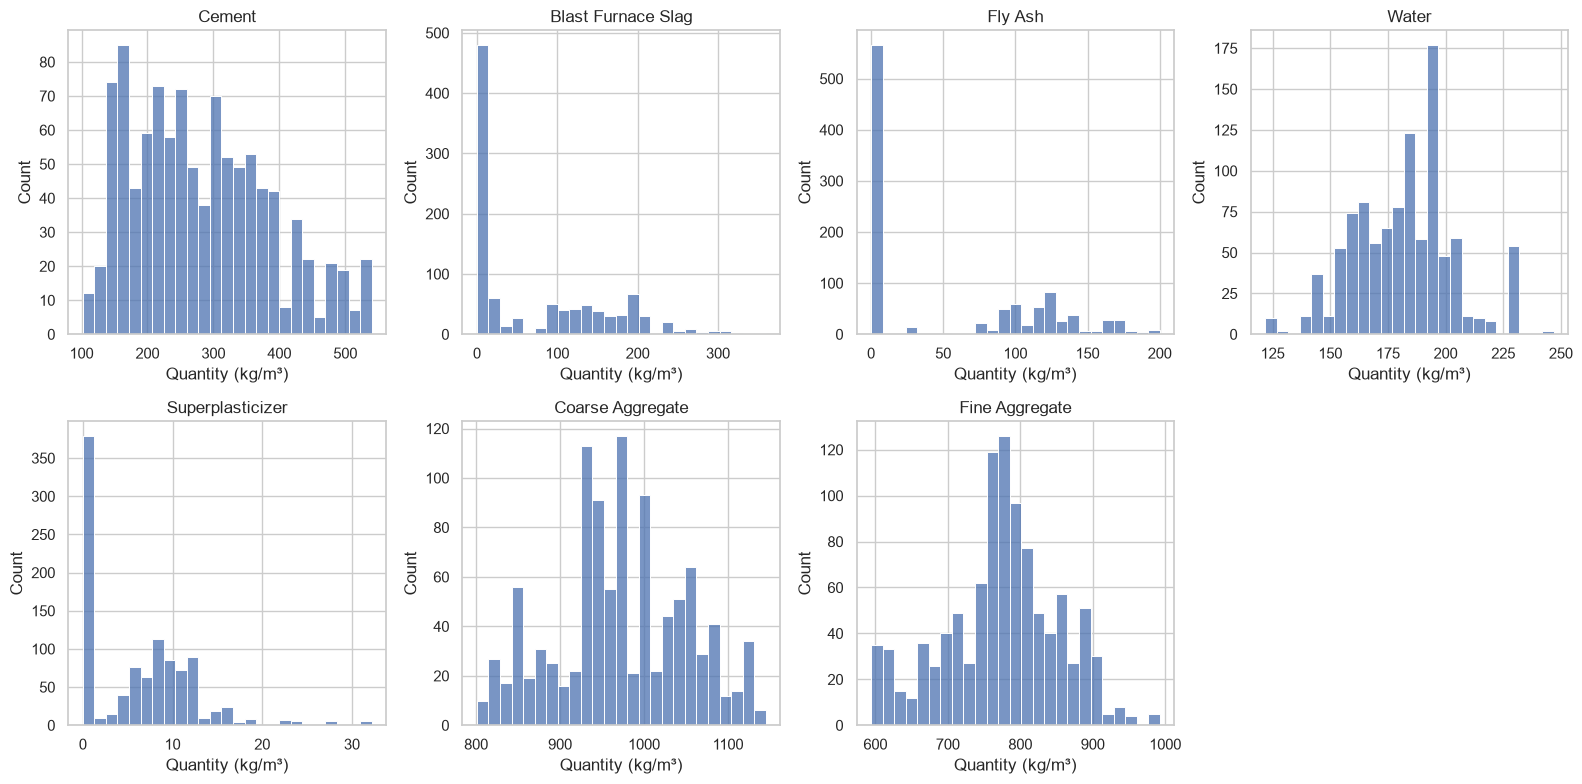

In [6]:
ingredients = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, column in zip(axes.flat, ingredients):
    sns.histplot(
        data=df,
        x=column,
        bins=25,
        ax=ax
    )
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Quantity (kg/m³)")

# Hide unused subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.savefig(
    fig_dir / "ingredient_distributions.png",
    dpi=300
)
plt.show()


### Ingredient Distribution — Observations

- **Cement:** Quantities vary considerably, with most samples containing approximately 150–400 kg/m³.
- **Blast Furnace Slag:** A large number of samples contain no slag, resulting in a strong concentration at zero.
- **Fly Ash:** Many samples contain zero fly ash, while nonzero quantities are distributed across a wide range.
- **Water:** Quantities are mainly concentrated between 150 and 200 kg/m³.
- **Superplasticizer:** Many mixtures contain no superplasticizer, and the distribution is strongly right-skewed.
- **Coarse Aggregate:** Quantities vary across a relatively broad range, with several concentrations.
- **Fine Aggregate:** Most quantities are concentrated around 700–850 kg/m³.

**Conclusion:** Ingredient quantities show different distribution patterns. Some ingredients, particularly slag, fly ash, and superplasticizer, are absent from many mixtures, while water and aggregate quantities are more concentrated.

These distributions describe ingredient usage but do not establish their relationships with concrete strength.


In [7]:
age_counts = df["age"].value_counts().sort_index()

display(
    age_counts.rename_axis("Age (days)")
              .reset_index(name="Number of Samples")
)


,Age (days),Number of Samples
0,1,2
1,3,134
2,7,126
3,14,62
4,28,425
5,56,91
6,90,54
7,91,22
8,100,52
9,120,3


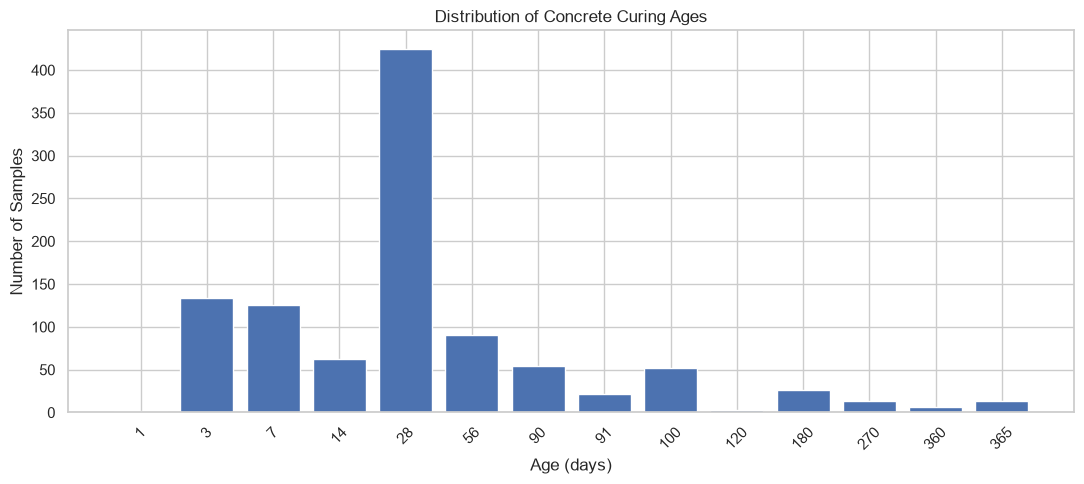

In [8]:
plt.figure(figsize=(11, 5))
plt.bar(    age_counts.index.astype(str),    age_counts.values)
plt.title("Distribution of Concrete Curing Ages")
plt.xlabel("Age (days)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(fig_dir / "age_distribution.png", dpi=300)
plt.show()


### Curing Age Distribution — Observations

- Curing ages range from 1 to 365 days.
- The most common curing age is 28 days (425 samples).
- The dataset contains 134 samples at 3 days and 126 at 7 days.
- Only 59 samples have curing ages between 180 and 365 days.
- The distribution is highly concentrated around 28 days.

**Conclusion:** The dataset contains an uneven distribution
of curing ages. This imbalance should be considered when
analyzing strength and evaluating model reliability.


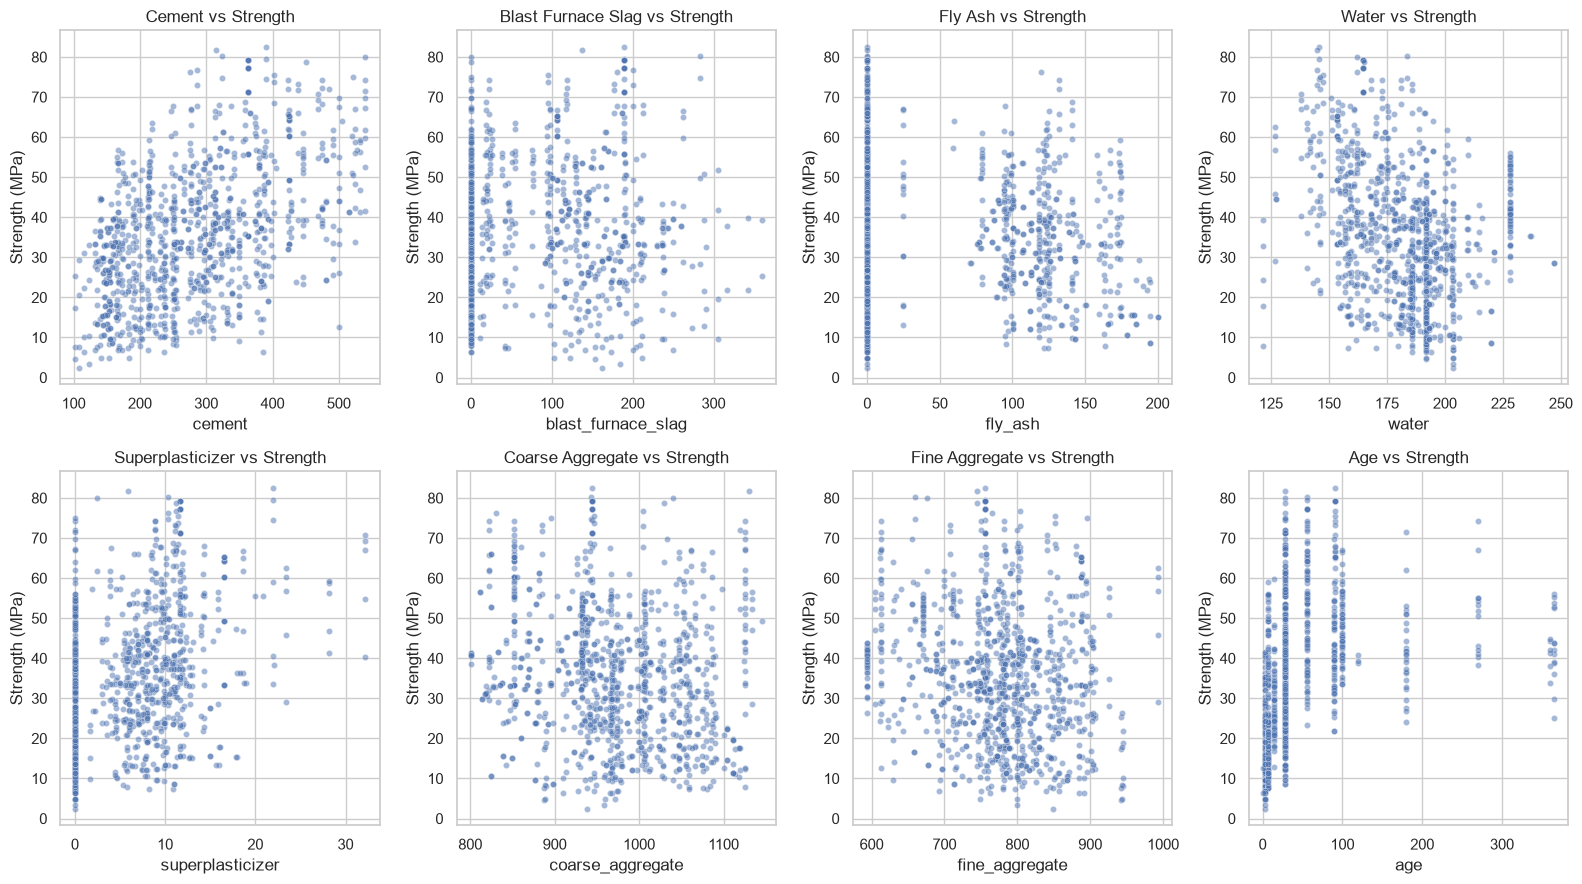

In [9]:
features = ingredients + ["age"]

fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for ax, feature in zip(axes.flat, features):

    sns.scatterplot(
        data=df,
        x=feature,
        y="strength",
        alpha=0.5,
        s=20,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title()
        + " vs Strength"
    )

    ax.set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.savefig(
    fig_dir / "feature_strength_relationships.png",
    dpi=300
)
plt.show()


### Relationships Between Features and Concrete Strength

Scatter plots were created to visually investigate how the seven concrete ingredients and curing age relate to compressive strength.

![Feature vs Strength Relationships](reports/figures/feature_strength_relationships.png)

#### Key Observations

- **Cement:** A clear positive association is visible. Higher cement quantities generally correspond to higher concrete strength.
- **Blast Furnace Slag:** No clear linear relationship is visible. Strength varies considerably across different slag quantities.
- **Fly Ash:** The relationship appears weak or unclear, with substantial variation in strength.
- **Water:** A negative association is visible. Higher water quantities generally correspond to lower concrete strength.
- **Superplasticizer:** A generally positive tendency is visible, although considerable variation exists.
- **Coarse Aggregate:** No strong positive relationship is apparent. A possible weak negative tendency can be observed.
- **Fine Aggregate:** No clear linear relationship is visible.
- **Curing Age:** Strength generally tends to increase with age, particularly at earlier ages. However, substantial variation exists, and older age groups contain fewer samples.

#### Conclusion

The scatter plots suggest that cement, water, superplasticizer, and curing age may have noticeable relationships with concrete compressive strength.

However, these visual patterns do not establish causation or measure the exact strength of the relationships.


**Next Step:** Pearson correlation analysis will be performed in Task #04 to quantify the direction and strength of linear relationships.


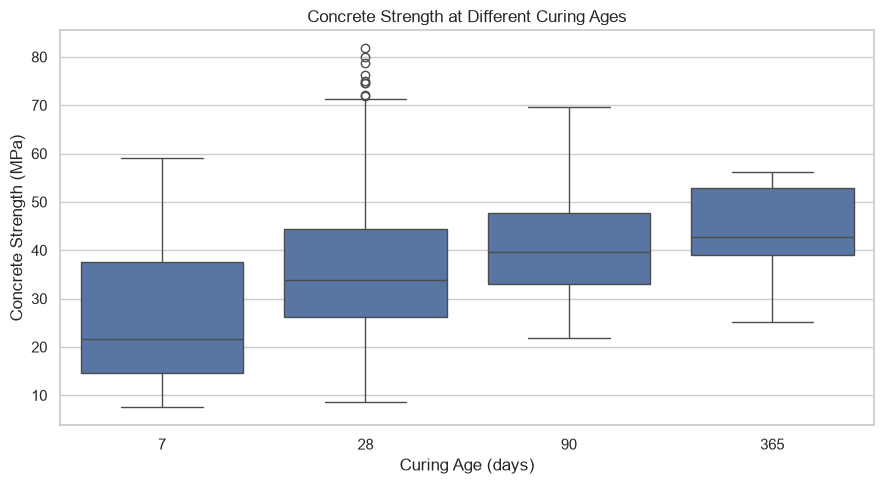

In [10]:
age_groups = [7, 28, 90, 365]

age_subset = df[df["age"].isin(age_groups)]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=age_subset,
    x="age",
    y="strength",
    order=age_groups
)

plt.title("Concrete Strength at Different Curing Ages")
plt.xlabel("Curing Age (days)")
plt.ylabel("Concrete Strength (MPa)")

plt.tight_layout()
plt.savefig(
    fig_dir / "strength_by_age.png",
    dpi=300
)
plt.show()


### Concrete Strength at Different Curing Ages

Box plots were used to compare concrete compressive strength across four curing ages: 7, 28, 90, and 365 days.

![Concrete Strength by Curing Age](reports/figures/strength_by_age.png)

#### Key Observations

- **7 Days:** The median concrete strength is approximately 22 MPa, indicating relatively low strength compared with older age groups.
- **28 Days:** The median strength increases to approximately 34 MPa. Several high-strength outliers are observed.
- **90 Days:** The median strength reaches approximately 40 MPa, showing a further increase.
- **365 Days:** The median strength is approximately 43 MPa, the highest among the four groups.

#### Conclusion

Concrete samples tested at older curing ages generally exhibit higher median compressive strengths.

However, considerable variation exists within each age group, and the number of observations differs between groups.

These comparisons do not establish that curing age alone causes the observed strength differences because concrete mixtures may have different ingredient quantities.

Further statistical analysis is required to understand the relationship between curing age and concrete strength.



## Task 03 — Exploratory Data Analysis Findings

### 1. Concrete Strength Distribution

- **Mean strength:** Approximately 35.82 MPa.
- **Median strength:** Approximately 34.44 MPa.
- **Minimum strength:** Approximately 2.33 MPa.
- **Maximum strength:** Approximately 82.60 MPa.
- **Standard deviation:** Approximately 16.71 MPa.
- **Distribution:** The strength distribution is approximately unimodal and slightly right-skewed.
- **Most common range:** A large concentration of samples falls between approximately 20 and 45 MPa.
- **Unusual observations:** Relatively few samples have strengths above 70 MPa.

**Finding:** Concrete strength varies considerably across the dataset, with most samples concentrated around moderate strength values.

### 2. Ingredient Distributions

- **Cement:** Most samples contain approximately 150–400 kg/m³, with fewer samples at higher quantities.
- **Water:** Quantities are mainly concentrated between 150 and 200 kg/m³.
- **Blast Furnace Slag:** Many mixtures contain zero slag, while nonzero quantities vary widely.
- **Fly Ash:** Many samples contain no fly ash, and the remaining quantities are spread across a broad range.
- **Superplasticizer:** Many mixtures contain zero superplasticizer, resulting in a strongly right-skewed distribution.
- **Coarse Aggregate:** Quantities are widely distributed, with noticeable concentrations around 950–1000 kg/m³.
- **Fine Aggregate:** Most quantities are concentrated around 700–850 kg/m³.

**Finding:** Ingredient quantities have different distribution patterns. Zero values for slag, fly ash, and superplasticizer indicate that these ingredients are absent from some mixtures, rather than necessarily representing missing data.

### 3. Curing Age Distribution

- **Minimum curing age:** 1 day.
- **Maximum curing age:** 365 days.
- **Most frequent curing age:** 28 days (425 samples).
- **3-day samples:** 134.
- **7-day samples:** 126.
- **Older samples (180–365 days):** 59.
- **Distribution:** Curing ages are unevenly distributed, with a strong concentration at 28 days.

#### Strength Comparison Across Curing Ages

Approximate median strengths observed from the box plots:

- **7 days:** 22 MPa.
- **28 days:** 34 MPa.
- **90 days:** 40 MPa.
- **365 days:** 43 MPa.

**Finding:** Older concrete samples generally have higher median strengths. However, different age groups contain different mixtures and unequal numbers of samples.

### 4. Relationships With Concrete Strength

Scatter plots were used to visually investigate relationships between input features and concrete compressive strength.

- **Cement vs Strength:** A noticeable positive association is observed. Higher cement quantities generally correspond to higher strengths.
- **Water vs Strength:** A negative association is visible. Higher water quantities generally correspond to lower strengths.
- **Age vs Strength:** Strength generally increases with curing age, particularly at earlier ages.
- **Blast Furnace Slag vs Strength:** No clear linear relationship is visible.
- **Fly Ash vs Strength:** The relationship appears weak or unclear, with considerable variation.
- **Superplasticizer vs Strength:** A generally positive tendency is visible, although substantial variation exists.
- **Coarse Aggregate vs Strength:** A possible weak negative tendency is observed.
- **Fine Aggregate vs Strength:** No clear linear relationship is visible.

**Finding:** Cement, water, superplasticizer, and curing age appear to have noticeable associations with concrete strength.

However, visual patterns alone cannot establish the strength, statistical significance, or causal nature of these relationships.

### 5. Limitations

- Visual relationships do not prove causation.
- Ingredient quantities may be related to one another, making individual effects difficult to isolate.
- Some relationships may be nonlinear.
- Curing age groups contain unequal sample sizes.
- The dataset contains 25 exact duplicate rows, which were retained for further investigation.
- Potential outliers were retained because unusual values are not necessarily incorrect measurements.
- These findings are exploratory and require further statistical analysis.

### Conclusion

Exploratory Data Analysis revealed important characteristics of the concrete dataset.

Concrete strength varies considerably, with most observations concentrated between approximately 20 and 45 MPa.

Cement content and curing age show generally positive associations with strength, while water content shows a negative association.

Ingredient distributions also reveal considerable variability, including mixtures containing no slag, fly ash, or superplasticizer.

These observations provide an initial understanding of the factors associated with concrete strength.

**Next Step:** Task #04 — Correlation Analysis will quantify the direction and strength of linear relationships using Pearson correlation coefficients.



---

# Task 04 — Correlation Analysis

## Objective

Measure the direction and strength of linear
relationships between concrete ingredients,
curing age, and compressive strength.

## Research Questions

1. Which ingredients have positive correlations with strength?
2. Which ingredients have negative correlations with strength?
3. Which features have the strongest linear relationships?
4. How are the input features related to one another?
5. Do duplicate observations affect the correlation results?

## Method

Pearson Correlation Coefficient (r)


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

paths = [
    Path("data/processed/concrete_clean.csv"),
    Path("../data/processed/concrete_clean.csv")
]

data_path = next((p for p in paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("Processed dataset not found.")

df = pd.read_csv(data_path)

project_root = data_path.parent.parent.parent
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [12]:
# Calculate Pearson correlation matrix
corr_matrix = df.corr(method="pearson")
# Display correlations
display(corr_matrix.round(3))


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
cement,1.000,-0.275,-0.397,-0.082,0.093,-0.109,-0.223,0.082,0.498
blast_furnace_slag,-0.275,1.000,-0.324,0.107,0.043,-0.284,-0.282,-0.044,0.135
fly_ash,-0.397,-0.324,1.000,-0.257,0.377,-0.010,0.079,-0.154,-0.106
water,-0.082,0.107,-0.257,1.000,-0.657,-0.182,-0.451,0.278,-0.290
superplasticizer,0.093,0.043,0.377,-0.657,1.000,-0.266,0.223,-0.193,0.366
coarse_aggregate,-0.109,-0.284,-0.010,-0.182,-0.266,1.000,-0.179,-0.003,-0.165
fine_aggregate,-0.223,-0.282,0.079,-0.451,0.223,-0.179,1.000,-0.156,-0.167
age,0.082,-0.044,-0.154,0.278,-0.193,-0.003,-0.156,1.000,0.329
strength,0.498,0.135,-0.106,-0.290,0.366,-0.165,-0.167,0.329,1.000



### Pearson Correlation Matrix — Initial Findings

#### Positive Correlations with Strength

- **Cement (r = +0.498):** Moderate positive correlation.
- **Superplasticizer (r = +0.366):** Moderate positive correlation.
- **Age (r = +0.329):** Moderate positive correlation.
- **Blast Furnace Slag (r = +0.135):** Weak positive correlation.

#### Negative Correlations with Strength

- **Water (r = -0.290):** Weak negative correlation.
- **Fine Aggregate (r = -0.167):** Weak negative correlation.
- **Coarse Aggregate (r = -0.165):** Weak negative correlation.
- **Fly Ash (r = -0.106):** Weak negative correlation.

#### Key Findings

1. Cement has the strongest positive linear correlation with concrete strength.
2. Water has the strongest negative linear correlation with concrete strength.
3. Fly ash has the weakest absolute linear correlation with strength.
4. Curing age and superplasticizer show moderate positive correlations.
5. Water and superplasticizer have a relatively strong negative correlation (r = -0.657).

#### Interpretation

The results suggest that cement content, superplasticizer,
and curing age are positively associated with concrete strength,
while water content is negatively associated with strength.

However, Pearson correlation measures linear association
and does not establish causation or independent effects.

Multivariable statistical modelling is required to
investigate these relationships further.


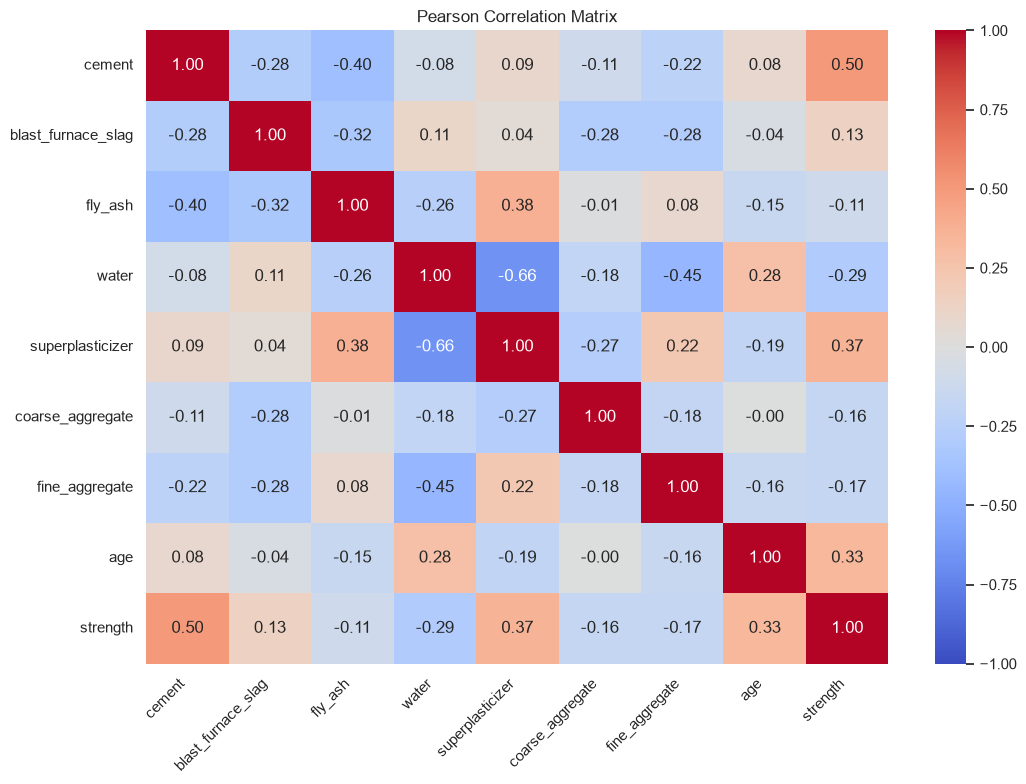

In [13]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Pearson Correlation Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    fig_dir / "correlation_heatmap.png",
    dpi=300
)

plt.show()


In [14]:
# Correlations with concrete strength
strength_corr = (
    corr_matrix["strength"]
    .drop("strength")
    .sort_values(ascending=False)
)

# Create summary table
correlation_results = pd.DataFrame({
    "Pearson r": strength_corr,
    "Absolute r": strength_corr.abs()
})

display(correlation_results.round(3))



,Pearson r,Absolute r
cement,0.498,0.498
superplasticizer,0.366,0.366
age,0.329,0.329
blast_furnace_slag,0.135,0.135
fly_ash,-0.106,0.106
coarse_aggregate,-0.165,0.165
fine_aggregate,-0.167,0.167
water,-0.290,0.290


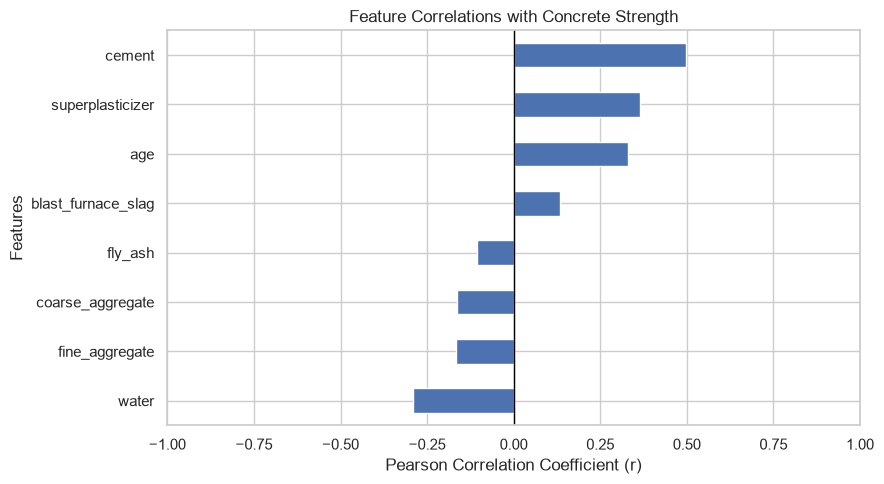

In [15]:
plt.figure(figsize=(9, 5))

strength_corr.sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlations with Concrete Strength")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.ylabel("Features")
plt.xlim(-1, 1)

plt.axvline(0, color="black", linewidth=1)

plt.tight_layout()

plt.savefig(
    fig_dir / "strength_correlations.png",
    dpi=300
)

plt.show()




### Pearson Correlation Matrix — Initial Findings

#### Positive Correlations with Strength

- **Cement (r = +0.498):** Moderate positive correlation.
- **Superplasticizer (r = +0.366):** Moderate positive correlation.
- **Age (r = +0.329):** Moderate positive correlation.
- **Blast Furnace Slag (r = +0.135):** Weak positive correlation.

#### Negative Correlations with Strength

- **Water (r = -0.290):** Weak negative correlation.
- **Fine Aggregate (r = -0.167):** Weak negative correlation.
- **Coarse Aggregate (r = -0.165):** Weak negative correlation.
- **Fly Ash (r = -0.106):** Weak negative correlation.

#### Key Findings

1. Cement has the strongest positive linear correlation with concrete strength.
2. Water has the strongest negative linear correlation with concrete strength.
3. Fly ash has the weakest absolute linear correlation with strength.
4. Curing age and superplasticizer show moderate positive correlations.
5. Water and superplasticizer have a relatively strong negative correlation (r = -0.657).

#### Interpretation

The results suggest that cement content, superplasticizer,
and curing age are positively associated with concrete strength,
while water content is negatively associated with strength.

However, Pearson correlation measures linear association
and does not establish causation or independent effects.

Multivariable statistical modelling is required to
investigate these relationships further.


In [16]:
# Input features only
features = df.drop(columns=["strength"])

# Correlations among input features
feature_matrix = features.corr(method="pearson")

# Extract unique feature pairs
upper_triangle = feature_matrix.where(
    np.triu(
        np.ones(feature_matrix.shape),
        k=1
    ).astype(bool)
)

feature_pairs = upper_triangle.stack()

# Rank by absolute correlation
strongest_pairs = feature_pairs.reindex(
    feature_pairs.abs().sort_values(
        ascending=False
    ).index
)

print("Strongest correlations between input features:")
display(strongest_pairs.head(10).round(3))



Strongest correlations between input features:


water               superplasticizer     -0.657
                    fine_aggregate       -0.451
cement              fly_ash              -0.397
fly_ash             superplasticizer      0.377
blast_furnace_slag  fly_ash              -0.324
                    coarse_aggregate     -0.284
                    fine_aggregate       -0.282
water               age                   0.278
cement              blast_furnace_slag   -0.275
superplasticizer    coarse_aggregate     -0.266
dtype: float64

In [17]:
# Dataset without exact duplicates
df_unique = df.drop_duplicates()

# Calculate correlations in both datasets
original_corr = df.corr()["strength"].drop("strength")
unique_corr = df_unique.corr()["strength"].drop("strength")

comparison = pd.DataFrame({
    "All Rows": original_corr,
    "Unique Rows": unique_corr
})

comparison["Difference"] = (
    comparison["All Rows"] -
    comparison["Unique Rows"]
)

display(comparison.round(4))

print("Original samples:", len(df))
print("Unique samples:", len(df_unique))


,All Rows,Unique Rows,Difference
cement,0.4978,0.4883,0.0095
blast_furnace_slag,0.1348,0.1034,0.0315
fly_ash,-0.1058,-0.0806,-0.0251
water,-0.2896,-0.2696,-0.0200
superplasticizer,0.3661,0.3442,0.0219
coarse_aggregate,-0.1649,-0.1447,-0.0202
fine_aggregate,-0.1672,-0.1865,0.0192
age,0.3289,0.3374,-0.0085


Original samples: 1030
Unique samples: 1005



### Duplicate Sensitivity Analysis

To investigate the effect of duplicate observations,
Pearson correlations were calculated using both the
original dataset and a version without exact duplicates.

#### Dataset Comparison

- Original observations: 1,030
- Unique observations: 1,005
- Exact duplicate rows: 25

#### Key Findings

- All correlation coefficients changed by less than approximately 0.032.
- The direction of every correlation remained unchanged.
- Cement remained the strongest positive correlate with strength.
- Water remained the strongest negative correlate with strength.
- The largest absolute change occurred for blast furnace slag (approximately 0.0315).

#### Conclusion

The correlation results were relatively insensitive
to the removal of exact duplicate records.

Therefore, the main exploratory correlation findings
remained consistent across both datasets.

However, duplicate records must still be handled
carefully during machine learning evaluation to avoid
data leakage.


## Task 04 — Correlation Analysis Findings

### 1. Positive Correlations

The following features showed positive Pearson correlations with concrete compressive strength:

- **Cement:** r = +0.4978
- **Superplasticizer:** r = +0.3661
- **Age:** r = +0.3289
- **Blast Furnace Slag:** r = +0.1348

**Interpretation:** Higher values of these features tend to be associated with higher concrete strength, although the relationships differ in magnitude.

### 2. Negative Correlations

The following features showed negative Pearson correlations with concrete compressive strength:

- **Water:** r = -0.2896
- **Fine Aggregate:** r = -0.1672
- **Coarse Aggregate:** r = -0.1649
- **Fly Ash:** r = -0.1058

**Interpretation:** Higher values of these features tend to be associated with lower concrete strength in the individual linear comparisons. This does not establish that the features cause strength to decrease.

### 3. Strongest Linear Relationships

- **Strongest positive correlation:** Cement (r = +0.4978)
- **Strongest negative correlation:** Water (r = -0.2896)
- **Weakest absolute linear correlation:** Fly Ash (r = -0.1058)
- **Strongest absolute correlation with strength:** Cement (|r| = 0.4978)

### 4. Correlations Between Input Features

Some input features were correlated with each other. Notable pairs include:

- **Water and Superplasticizer:** r = -0.657
- **Water and Fine Aggregate:** r = -0.451
- **Cement and Fly Ash:** r = -0.397
- **Fly Ash and Superplasticizer:** r = +0.377
- **Blast Furnace Slag and Fly Ash:** r = -0.324

**Interpretation:** Ingredient quantities are not fully independent. These associations will be considered during multivariable statistical modelling, including checks for multicollinearity.

### 5. Duplicate Sensitivity Analysis

Pearson correlations were recalculated after removing exact duplicate rows *temporarily for comparison*.

- **Original observations:** 1,030
- **Observations after removing exact duplicates:** 1,005
- **Exact duplicate rows:** 25
- **Largest absolute correlation change:** Approximately 0.0315 (Blast Furnace Slag)
- **Direction of correlations:** Unchanged for all eight features
- **Key ranking:** Cement remained the strongest positive correlate, and water remained the strongest negative correlate.

**Interpretation:** Removing exact duplicates caused only small changes to the correlations, suggesting the main descriptive findings are not highly sensitive to those repeated records. Duplicates still require careful handling before machine-learning train/test evaluation.

### 6. Limitations

- Correlation does not establish causation.
- Pearson correlation measures **linear** relationships; nonlinear patterns may not be captured.
- A feature's correlation does not isolate its effect while holding other ingredients constant.
- Correlations between predictors may complicate interpretation in multiple regression.
- The dataset includes repeated observations and unevenly represented curing ages.
- These findings are exploratory and should not be used alone to choose final prediction features.

### Conclusion

Pearson correlation analysis quantified the direction and strength of linear relationships between concrete ingredients, curing age, and compressive strength.

Cement showed the strongest positive correlation with strength (**r = +0.4978**), while water showed the strongest negative correlation (**r = -0.2896**). Superplasticizer and age also showed positive associations. Correlations between input features, especially water and superplasticizer, indicate that relationships should be examined jointly rather than interpreted in isolation.







---

# **Task 05 — Statistical Modelling & Interpretation**

## Objective

Investigate how concrete ingredients and curing age
are associated with compressive strength when
analyzed together using Multiple Linear Regression.

## Research Questions

1. Which variables have positive regression coefficients?
2. Which variables have negative regression coefficients?
3. Which associations are statistically significant?
4. How much variation in strength does the model explain?
5. Does multicollinearity affect model interpretation?
6. Are the assumptions of linear regression reasonable?

## Method

Ordinary Least Squares (OLS) Multiple Linear Regression
using Statsmodels.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# Locate processed dataset
paths = [
    Path("data/processed/concrete_clean.csv"),
    Path("../data/processed/concrete_clean.csv")
]

data_path = next((p for p in paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("Processed dataset not found.")

df = pd.read_csv(data_path)

project_root = data_path.parent.parent.parent
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

print("Dataset shape:", df.shape)


Dataset shape: (1030, 9)


In [13]:
feature_cols = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age"
]

# Identical input mixtures receive the same group ID
groups = pd.util.hash_pandas_object(
    df[feature_cols],
    index=False
)

# Split by groups to prevent identical mixtures
# appearing in both training and test datasets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=groups)
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# Verify that groups do not overlap
assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[test_idx])
)

# Save the split for all future ML tasks
train_df.to_csv(
    data_path.parent / "train_data.csv",
    index=False
)

test_df.to_csv(
    data_path.parent / "test_data.csv",
    index=False
)

print("Training observations:", len(train_df))
print("Test observations:", len(test_df))
print("No identical input mixtures across splits.")


Training observations: 828
Test observations: 202
No identical input mixtures across splits.


In [14]:
train_analysis = train_df.drop_duplicates().copy()

X = train_analysis[feature_cols]
y = train_analysis["strength"]

print("Statistical analysis samples:", len(train_analysis))
print("Features:", X.shape[1])


Statistical analysis samples: 803
Features: 8



### Statistical Analysis Data Preparation

The dataset was divided into training and test subsets
using a group-aware split to prevent identical concrete
mixtures from appearing in both subsets.

#### Results

- Total observations: 1,030
- Training observations: 828 (80.4%)
- Test observations: 202 (19.6%)
- Unique training observations: 803
- Number of input features: 8

#### Preprocessing Decision

The 25 exact duplicate rows in the training subset
were excluded from the exploratory OLS analysis.

The test dataset was reserved for future model evaluation
and was not used for statistical model fitting.

#### Conclusion

The statistical analysis dataset is prepared,
with duplicate-related leakage between training
and test sets prevented by grouping identical inputs.


In [15]:
# Add the intercept
X_sm = sm.add_constant(X, has_constant="add")

# Fit Ordinary Least Squares regression
model = sm.OLS(y, X_sm)

# HC3 provides heteroscedasticity-robust standard errors
results = model.fit(cov_type="HC3")

# Display statistical summary
print(results.summary())


                            OLS Regression Results                            
Dep. Variable:               strength   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.609
Method:                 Least Squares   F-statistic:                     121.9
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          1.36e-132
Time:                        14:28:27   Log-Likelihood:                -3003.7
No. Observations:                 803   AIC:                             6025.
Df Residuals:                     794   BIC:                             6068.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                -16.4890     34


### Multiple Linear Regression — Initial Results

#### Model Information

- Method: Ordinary Least Squares (OLS)
- Covariance estimator: HC3 robust
- Training observations: 803
- Number of input variables: 8
- R-squared: 0.613
- Adjusted R-squared: 0.609

#### Model Fit

The multiple regression model explains approximately
61.3% of the variation in concrete strength within
the fitted training dataset.

This represents in-sample explanatory performance,
not predictive accuracy on unseen data.

#### Positive Regression Coefficients

- Cement: +0.1185 (p < 0.001)
- Blast Furnace Slag: +0.0986 (p < 0.001)
- Fly Ash: +0.0862 (p < 0.001)
- Superplasticizer: +0.2570 (p = 0.035)
- Coarse Aggregate: +0.0141 (p = 0.233)
- Fine Aggregate: +0.0219 (p = 0.105)
- Age: +0.1174 (p < 0.001)

#### Negative Regression Coefficients

- Water: -0.1688 (p = 0.001)

#### Statistical Significance

At the 5% significance level, cement, blast furnace
slag, fly ash, water, superplasticizer, and age
have statistically significant coefficients.

Coarse aggregate and fine aggregate do not have
statistically significant coefficients at this level.

#### Interesting Finding: Fly Ash

Fly ash showed a negative Pearson correlation with
strength (r = -0.106) in Task 04.

However, its coefficient in multiple regression
is positive (+0.0862).

This difference indicates that the association
changes after accounting for other predictors.

#### Important Limitations

- Regression coefficients represent conditional
  associations, not proven causal effects.
- Coefficients cannot be directly compared to rank
  ingredient importance because measurement scales differ.
- The high condition number requires further investigation.
- Linear relationships may not fully describe the
  behavior of concrete strength.

#### Initial Conclusion

Multiple regression reveals relationships that are
not always apparent from simple correlation analysis.

Further diagnostics are required before drawing
final statistical conclusions.


In [16]:
coef_table = pd.DataFrame({
    "Coefficient": results.params,
    "P-value": results.pvalues,
    "CI Lower": results.conf_int()[0],
    "CI Upper": results.conf_int()[1]
})

display(coef_table.round(4))


,Coefficient,P-value,CI Lower,CI Upper
const,-16.4890,0.6295,-83.4799,50.5020
cement,0.1185,0.0000,0.0977,0.1394
blast_furnace_slag,0.0986,0.0000,0.0732,0.1239
fly_ash,0.0862,0.0000,0.0567,0.1157
water,-0.1688,0.0015,-0.2728,-0.0647
superplasticizer,0.2570,0.0346,0.0186,0.4953
coarse_aggregate,0.0141,0.2330,-0.0090,0.0372
fine_aggregate,0.0219,0.1048,-0.0046,0.0484
age,0.1174,0.0000,0.0986,0.1363



### Regression Coefficients and Confidence Intervals

The OLS regression model was fitted using HC3 robust
standard errors.

#### Statistically Significant Variables (p < 0.05)

- Cement: +0.1185
- Blast Furnace Slag: +0.0986
- Fly Ash: +0.0862
- Water: -0.1688
- Superplasticizer: +0.2570
- Age: +0.1174

#### Statistically Non-Significant Variables (p >= 0.05)

- Coarse Aggregate: +0.0141 (p = 0.2330)
- Fine Aggregate: +0.0219 (p = 0.1048)

#### Confidence Interval Interpretation

The 95% confidence intervals of the six statistically
significant predictors exclude zero.

The confidence intervals of coarse aggregate and
fine aggregate include zero, indicating insufficient
evidence of nonzero coefficients at the 5% level.

#### Conclusion

Six predictors showed statistically significant
conditional associations with concrete strength.

However, statistical significance does not establish
causation or practical importance.

The results require further evaluation for
multicollinearity and regression assumptions.


In [17]:
print("R-squared:", round(results.rsquared, 4))
print("Adjusted R-squared:", round(results.rsquared_adj, 4))


R-squared: 0.6133
Adjusted R-squared: 0.6094



## Task 05 — Statistical Modelling Findings

### 1. Regression Model

Multiple Linear Regression was performed using
Ordinary Least Squares (OLS).

The model included seven concrete ingredients
and curing age as explanatory variables.

Exact duplicate rows were excluded from the
training portion for this exploratory analysis.

### 2. Regression Coefficients

#### Positive Coefficients


- Cement: Coefficient = +0.1185, p < 0.001
- Blast Furnace Slag: Coefficient = +0.0986, p < 0.001
- Fly Ash: Coefficient = +0.0862, p < 0.001
- Superplasticizer: Coefficient = +0.2570, p = 0.0346
- Coarse Aggregate: Coefficient = +0.0141, p = 0.2330
- Fine Aggregate: Coefficient = +0.0219, p = 0.1048
- Age: Coefficient = +0.1174, p < 0.001


#### Negative Coefficients

- Water: Coefficient = -0.1688, p = 0.0015


### 3. Statistical Significance

- Variables with p < 0.05: Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Age.
- Variables with p >= 0.05: Coarse Aggregate, Fine Aggregate.


Statistical significance was interpreted alongside
coefficient estimates and confidence intervals.

### 4. Model Fit

 R-squared: 0.6133
- Adjusted R-squared: 0.6094


Interpretation:

The model explains approximately 61.33% of the
variation in concrete compressive strength in the
training data. After adjusting for the number of
predictors, approximately 60.94% of the variation
is explained.


### 5. Multicollinearity

- Highest VIF: cement and 7.187
- Features requiring attention: cement

### 6. Regression Diagnostics

- Residual pattern: [Observation]
- Q-Q plot: Points roughly following the diagonal are more consistent with normally distributed errors. Strong deviations can indicate skewness, heavy tails, or other distributional differences.
- Breusch-Pagan p-value: 0.0

### 7. Limitations

- Results describe associations, not causal effects.
- The model assumes linear relationships in its predictors.
- Concrete strength may depend on nonlinear relationships.
- Related ingredient quantities can complicate interpretation.
- Statistical inference depends on model assumptions.
- Model fit on training data does not establish
  prediction performance on unseen data.

### Conclusion

Multiple Linear Regression was used to investigate
how concrete ingredients and curing age are
associated with strength when analyzed together.

The results provided adjusted associations,
statistical uncertainty estimates, and evidence
about the adequacy of a linear model.

Further analysis is needed before making causal
or practical engineering conclusions.


In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_table = pd.DataFrame({
    "Feature": feature_cols,
    "VIF": [
        variance_inflation_factor(
            X_sm.values,
            X_sm.columns.get_loc(col)
        )
        for col in feature_cols
    ]
})

display(
    vif_table.sort_values(
        "VIF",
        ascending=False
    ).round(3)
)

,Feature,VIF
0,cement,7.187
1,blast_furnace_slag,6.889
6,fine_aggregate,6.698
3,water,6.550
2,fly_ash,5.986
5,coarse_aggregate,4.901
4,superplasticizer,2.837
7,age,1.113


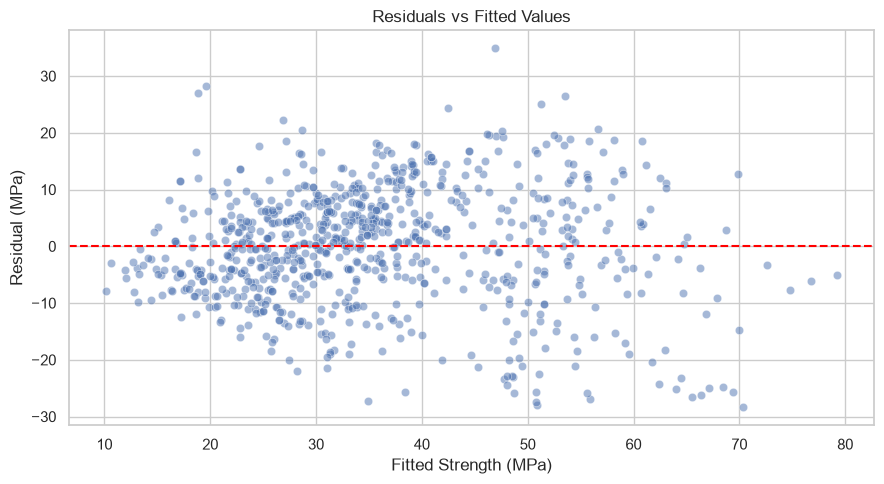

In [20]:
fitted = results.fittedvalues
residuals = results.resid
plt.figure(figsize=(9, 5))
sns.scatterplot(    x=fitted,    y=residuals,    alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Fitted Values")
plt.xlabel("Fitted Strength (MPa)")
plt.ylabel("Residual (MPa)")
plt.tight_layout()
plt.savefig(    fig_dir / "ols_residuals_vs_fitted.png",    dpi=300)
plt.show()


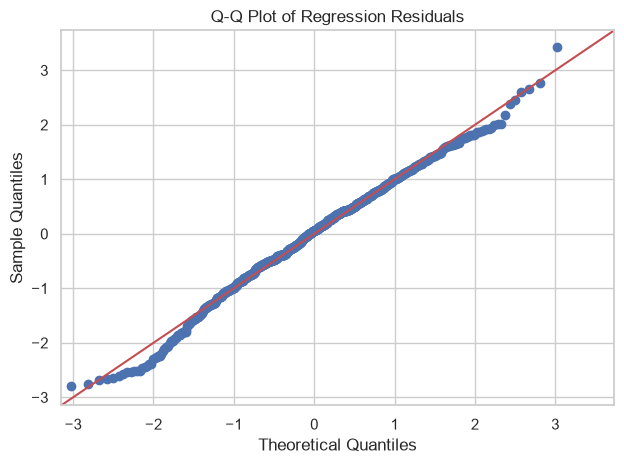

In [23]:
fig = sm.qqplot(    residuals,    line="45",    fit=True)
plt.title("Q-Q Plot of Regression Residuals")
plt.tight_layout()
fig.savefig(    fig_dir / "ols_residuals_qqplot.png",    dpi=300)
plt.show()


In [24]:
from statsmodels.stats.diagnostic import het_breuschpagan
bp_test = het_breuschpagan(    results.resid,    X_sm)
print("Breusch-Pagan p-value:", round(bp_test[1], 5))


Breusch-Pagan p-value: 0.0



## Task 05 — Statistical Modelling Findings

### 1. Regression Model

Multiple Linear Regression was performed using
Ordinary Least Squares (OLS).

The model included seven concrete ingredients
and curing age as explanatory variables.

Exact duplicate rows were excluded from the
training portion for this exploratory analysis.

### 2. Regression Coefficients

#### Positive Coefficients

- [Feature]: Coefficient = [Value], p = [Value]
- [Feature]: Coefficient = [Value], p = [Value]

#### Negative Coefficients

- [Feature]: Coefficient = [Value], p = [Value]
- [Feature]: Coefficient = [Value], p = [Value]

### 3. Statistical Significance

- Variables with p < 0.05: [List]
- Variables with p >= 0.05: [List]

Statistical significance was interpreted alongside
coefficient estimates and confidence intervals.

### 4. Model Fit

- R-squared: [Value]
- Adjusted R-squared: [Value]

Interpretation:
[Explain how much fitted-data variation was explained.]

### 5. Multicollinearity

- Highest VIF: [Feature and value]
- Features requiring attention: [List]

### 6. Regression Diagnostics

- Residual pattern: [Observation]
- Q-Q plot: [Observation]
- Breusch-Pagan p-value: [Value]

### 7. Limitations

- Results describe associations, not causal effects.
- The model assumes linear relationships in its predictors.
- Concrete strength may depend on nonlinear relationships.
- Related ingredient quantities can complicate interpretation.
- Statistical inference depends on model assumptions.
- Model fit on training data does not establish
  prediction performance on unseen data.

### Conclusion

Multiple Linear Regression was used to investigate
how concrete ingredients and curing age are
associated with strength when analyzed together.

The results provided adjusted associations,
statistical uncertainty estimates, and evidence
about the adequacy of a linear model.

Further analysis is needed before making causal
or practical engineering conclusions.



## Statistical Modelling & Interpretation

Multiple Linear Regression was performed using
Ordinary Least Squares (OLS) to investigate how
concrete ingredients and curing age are associated
with compressive strength when considered together.

### Analysis Performed

- Multiple Linear Regression using Statsmodels
- Regression coefficient interpretation
- P-values and 95% confidence intervals
- R-squared and Adjusted R-squared
- Multicollinearity analysis using VIF
- Residual diagnostics
- Breusch-Pagan test

### Key Findings

- **R-squared:** 0.6133
- **Adjusted R-squared:** 0.6094
- **Main positive associations:** Cement (+0.1185), Blast Furnace Slag (+0.0986), Fly Ash (+0.0862), Superplasticizer (+0.2570), and Age (+0.1174).
- **Main negative associations:** Water (-0.1688).
- **Multicollinearity findings:** Cement had the highest VIF of 7.187, indicating potential multicollinearity that requires attention.
- **Regression diagnostic findings:** Residual plots indicated heteroscedasticity. The Q-Q plot showed some deviations from normality at the tails. The Breusch-Pagan test confirmed evidence of heteroscedasticity (p-value approximately 0.0).

### Regression Diagnostics

![OLS Residuals vs Fitted](reports/figures/ols_residuals_vs_fitted.png)

![OLS Q-Q Plot](reports/figures/ols_residuals_qqplot.png)

### Detailed Analysis

Full statistical results and interpretations
are available in the
[Statistical Analysis Notebook](notebooks/03_statistical_analysis.ipynb).

### Next Step

Task #06 — Statistical Findings & Conclusions.
